In [4]:
#Smartphone Clustering Analysis

#Objective

#The objective of this track is to group similar smartphones based on their specifications using unsupervised machine learning.

#Algorithms

#1. K-Means Clustering
#2. Agglomerative Hierarchical Clustering

#Workflow

#1. Load and inspect the dataset.
#2. Perform exploratory data analysis.
#3. Clean and preprocess the features.
#4. Scale numerical features.
#5. Use the Elbow method to investigate a suitable number of clusters.
#6. Train K-Means and Agglomerative Clustering.
#7. Evaluate clusters using Silhouette Score, Davies–Bouldin Index, and Calinski–Harabasz Index.
#8. Visualize clusters using PCA and t-SNE.

#Important Note

#Clustering is an unsupervised learning task. Target labels, if available, will not be used to fit the clustering algorithms.

In [5]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

from scipy.cluster.hierarchy import dendrogram, linkage

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


In [9]:
df = pd.read_csv("../data/clustering.csv", sep=",")

if df.shape[1] == 1:
    df = df.iloc[:, 0].str.split(",", expand=True)

df.columns = [
    "id", "battery_power", "blue", "clock_speed", "dual_sim",
    "fc", "four_g", "int_memory", "m_dep", "mobile_wt",
    "n_cores", "pc", "px_height", "px_width", "ram",
    "sc_h", "sc_w", "talk_time", "three_g", "touch_screen", "wifi"
]

df = df.apply(pd.to_numeric, errors="coerce")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1000, 21)


,id,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,...,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi
0,1,1043,1,1.8,1,14,0,5,0.1,193,...,16,226,1412,3476,12,7,2,0,1,0
1,2,841,1,0.5,1,4,1,61,0.8,191,...,12,746,857,3895,6,0,7,1,0,0
2,3,1807,1,2.8,0,1,0,27,0.9,186,...,4,1270,1366,2396,17,10,10,0,1,1
3,4,1546,0,0.5,1,18,1,25,0.5,96,...,20,295,1752,3893,10,0,7,1,1,0
4,5,1434,0,1.4,0,11,1,49,0.5,108,...,18,749,810,1773,15,8,7,1,0,1


In [10]:
# Dataset audit

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nSummary statistics:")
display(df.describe().T)

Dataset shape: (1000, 21)

Column names:
['id', 'battery_power', 'blue', 'clock_speed', 'dual_sim', 'fc', 'four_g', 'int_memory', 'm_dep', 'mobile_wt', 'n_cores', 'pc', 'px_height', 'px_width', 'ram', 'sc_h', 'sc_w', 'talk_time', 'three_g', 'touch_screen', 'wifi']

Data types:
id                 int64
battery_power      int64
blue               int64
clock_speed      float64
dual_sim           int64
fc                 int64
four_g             int64
int_memory         int64
m_dep            float64
mobile_wt          int64
n_cores            int64
pc                 int64
px_height          int64
px_width           int64
ram                int64
sc_h               int64
sc_w               int64
talk_time          int64
three_g            int64
touch_screen       int64
wifi               int64
dtype: object

Missing values:
id               0
battery_power    0
blue             0
clock_speed      0
dual_sim         0
fc               0
four_g           0
int_memory       0
m_dep         

,count,mean,std,min,25%,50%,75%,max
id,1000.0,500.5000,288.819436,1.0,250.75,500.5,750.25,1000.0
battery_power,1000.0,1248.5100,432.458227,500.0,895.00,1246.5,1629.25,1999.0
blue,1000.0,0.5160,0.499994,0.0,0.00,1.0,1.00,1.0
clock_speed,1000.0,1.5409,0.829268,0.5,0.70,1.5,2.30,3.0
dual_sim,1000.0,0.5170,0.499961,0.0,0.00,1.0,1.00,1.0
fc,1000.0,4.5930,4.463325,0.0,1.00,3.0,7.00,19.0
four_g,1000.0,0.4870,0.500081,0.0,0.00,0.0,1.00,1.0
int_memory,1000.0,33.6520,18.128694,2.0,18.00,34.5,49.00,64.0
m_dep,1000.0,0.5175,0.280861,0.1,0.30,0.5,0.80,1.0
mobile_wt,1000.0,139.5110,34.851550,80.0,109.75,139.0,170.00,200.0


In [11]:
# Prepare features for clustering

# Remove the identifier column
X_cluster = df.drop(columns=["id"])

# Check for missing values
print("Missing values before imputation:", X_cluster.isnull().sum().sum())

# Handle missing values using median imputation
imputer = SimpleImputer(strategy="median")
X_cluster_imputed = imputer.fit_transform(X_cluster)

# Scale all features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster_imputed)

print("Original feature shape:", X_cluster.shape)
print("Scaled feature shape:", X_scaled.shape)
print("Missing values after imputation:", np.isnan(X_scaled).sum())

Missing values before imputation: 0
Original feature shape: (1000, 20)
Scaled feature shape: (1000, 20)
Missing values after imputation: 0


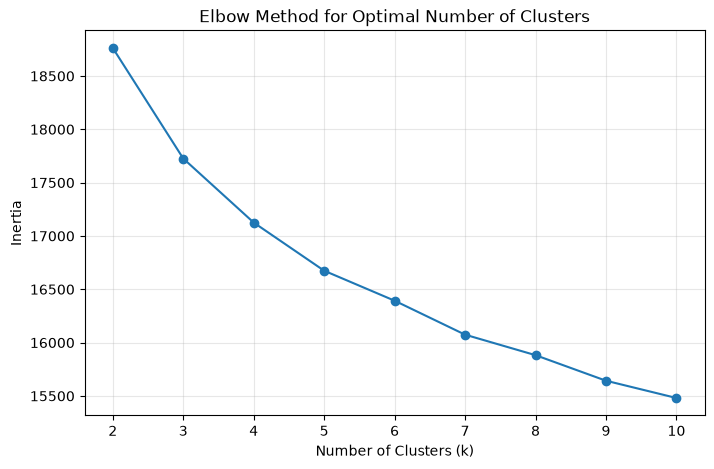

In [12]:
# Elbow Method for K-Means

inertia_values = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia_values.append(kmeans.inertia_)

# Plot Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker="o")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)
plt.show()

In [13]:
# K-Means Clustering

optimal_k = 5

kmeans_model = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_model.fit_predict(X_scaled)

print("K-Means clustering completed.")
print("Number of clusters:", optimal_k)
print("\nCluster sizes:")
print(pd.Series(kmeans_labels).value_counts().sort_index())

K-Means clustering completed.
Number of clusters: 5

Cluster sizes:
0    160
1    179
2    224
3    198
4    239
Name: count, dtype: int64


In [14]:
# Evaluate K-Means clustering

kmeans_silhouette = silhouette_score(X_scaled, kmeans_labels)
kmeans_db = davies_bouldin_score(X_scaled, kmeans_labels)
kmeans_ch = calinski_harabasz_score(X_scaled, kmeans_labels)

kmeans_metrics = pd.DataFrame([{
    "Algorithm": "K-Means",
    "Number of Clusters": optimal_k,
    "Silhouette Score": kmeans_silhouette,
    "Davies-Bouldin Index": kmeans_db,
    "Calinski-Harabasz Index": kmeans_ch
}])

display(kmeans_metrics.round(4))

,Algorithm,Number of Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,5,0.0511,3.0753,49.6166


In [15]:
# Agglomerative Hierarchical Clustering

agg_model = AgglomerativeClustering(
    n_clusters=5,
    linkage="ward"
)

agg_labels = agg_model.fit_predict(X_scaled)

print("Agglomerative clustering completed.")
print("Number of clusters:", len(np.unique(agg_labels)))

print("\nCluster sizes:")
print(pd.Series(agg_labels).value_counts().sort_index())

Agglomerative clustering completed.
Number of clusters: 5

Cluster sizes:
0    235
1    293
2    141
3    242
4     89
Name: count, dtype: int64


In [16]:
# Evaluate Agglomerative Clustering

agg_silhouette = silhouette_score(X_scaled, agg_labels)
agg_db = davies_bouldin_score(X_scaled, agg_labels)
agg_ch = calinski_harabasz_score(X_scaled, agg_labels)

agg_metrics = pd.DataFrame([{
    "Algorithm": "Agglomerative",
    "Number of Clusters": 5,
    "Silhouette Score": agg_silhouette,
    "Davies-Bouldin Index": agg_db,
    "Calinski-Harabasz Index": agg_ch
}])

display(agg_metrics.round(4))

,Algorithm,Number of Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,Agglomerative,5,0.0238,3.9608,30.8067


In [17]:
# Compare K-Means and Agglomerative Clustering

clustering_comparison = pd.concat(
    [kmeans_metrics, agg_metrics],
    ignore_index=True
)

display(clustering_comparison.round(4))

,Algorithm,Number of Clusters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,5,0.0511,3.0753,49.6166
1,Agglomerative,5,0.0238,3.9608,30.8067


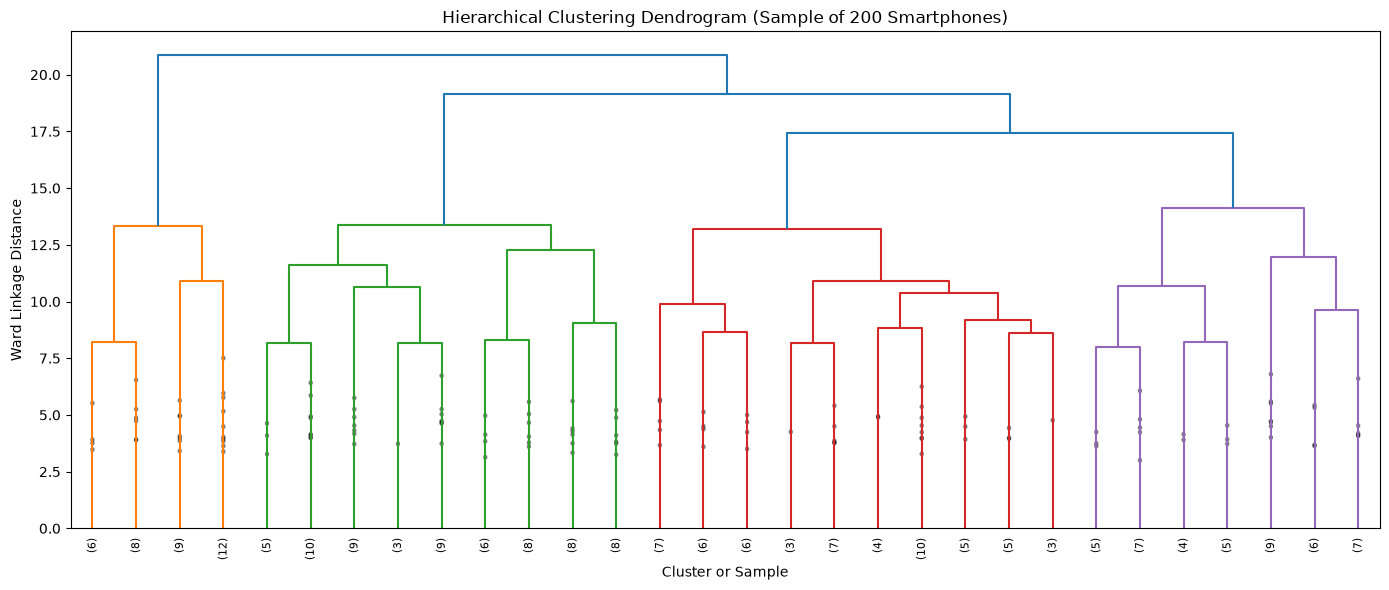

In [18]:
# Dendrogram for Agglomerative Hierarchical Clustering

from scipy.cluster.hierarchy import dendrogram, linkage

# Sample 200 rows for visualization
X_dendrogram = X_scaled[:200]

# Compute hierarchical linkage
linked = linkage(X_dendrogram, method="ward")

plt.figure(figsize=(14, 6))

dendrogram(
    linked,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90,
    leaf_font_size=8,
    show_contracted=True
)

plt.title("Hierarchical Clustering Dendrogram (Sample of 200 Smartphones)")
plt.xlabel("Cluster or Sample")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.show()

Variance explained by two components: 0.1662


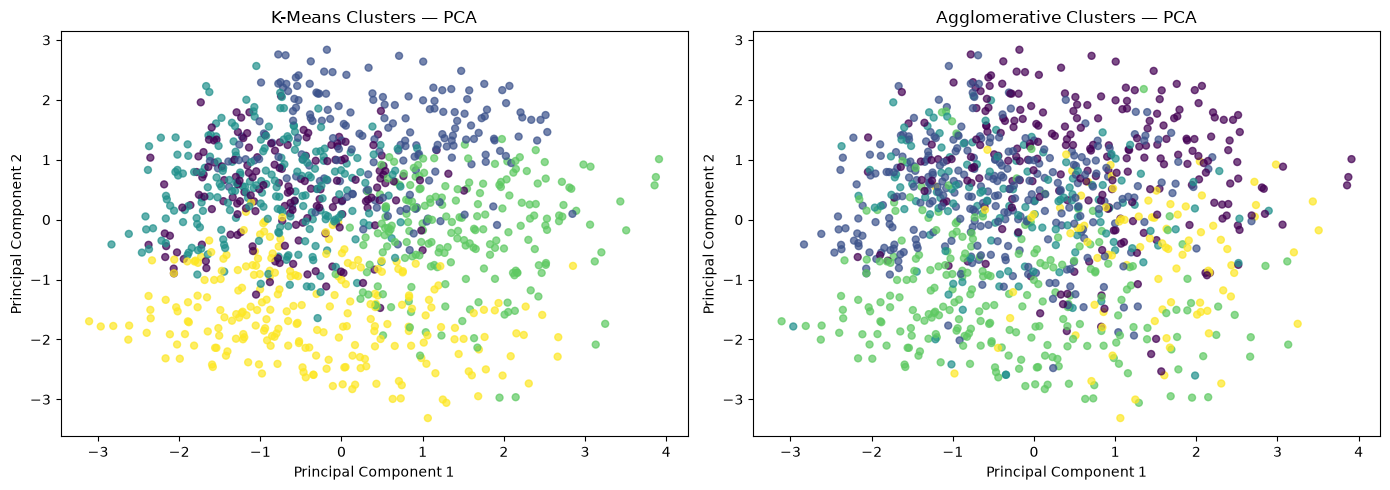

In [19]:
# PCA visualization of clustering results

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print(
    "Variance explained by two components:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=25,
    alpha=0.7
)
axes[0].set_title("K-Means Clusters — PCA")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")

axes[1].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=agg_labels,
    cmap="viridis",
    s=25,
    alpha=0.7
)
axes[1].set_title("Agglomerative Clusters — PCA")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

In [ ]:
# t-SNE visualization of K-Means clusters

tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=42
)

X_tsne = tsne.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))

plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    s=25,
    alpha=0.7
)

plt.title("K-Means Clusters — t-SNE Visualization")
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.tight_layout()
plt.show()